# Music Memory task — practice analysis

This notebook walks through a **simulated** Pavlovia download for the Music Memory task.
The people in these files are not real participants. The files are formatted the way a real
Pavlovia CSV will look, including the messy parts, so you can practice the cleaning before the study data arrive.

The practice files are in `fake_data/`, next to this notebook. `fake_data/answer_key.json` records the effects that were built into the simulation.
The last section checks your results against that key.


## 1. The task on one page

Each person sits through three parts, in this order:

1. **Encoding.** 108 short videos (9 blocks of 12). During each video they press **F** for one person or fewer, or **J** for more than one person. One third of the videos have no music, one third play a song from their youth (**MEAM**), and one third play a control song.
2. **Memory test.** 216 videos (the 108 they saw, plus 108 new lures). **Left arrow = OLD**, **right arrow = NEW**. Then confidence: **1 = Sure, 2 = Maybe, 3 = Guess**. If they said OLD, they also answer a source question: **1 = No music, 2 = Music you knew, 3 = Music you did not know**.
3. **Music survey.** Each of the 72 songs plays again. Four questions, clicked from 1 to 5: familiarity, autobiographical memory, self-relevance, and liking. A question left unanswered for 4 seconds is a timeout.

```text
Pavlovia CSV
├── plugin rows     row_type is blank     one row per screen jsPsych showed
└── tidy rows       row_type is filled    the rows this notebook analyzes
```

The tidy rows are written in one batch at the end of the session. They all share the same `trial_index`.
A second kind of file is in `recovered_localstorage/`: someone closed the browser during the memory test.
Pavlovia never received their CSV. The JSON is the browser backup, and `completed_session` is 0.


## 2. Open one raw file

Read one CSV with two settings that matter:

- `dtype=str` keeps every value as text, so a blank cell and the number 0 stay distinguishable while you look around.
- `keep_default_na=False` keeps the letters `null` as the word null. The default reader turns that word, and blank cells, into missing values.

jsPsych writes the word `null` when a screen ends with no keypress. On a tidy row, the same event is a blank `response` and a blank `rt_ms`.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, ttest_rel

# The notebook lives in training/. Running it from the repo root still finds the files.
HERE = Path.cwd()
if not (HERE / "fake_data").exists():
    HERE = HERE / "training"
DATA = HERE / "fake_data"

# Same column list as DATA_COLUMNS in js/datasaver.js.
DATA_COLUMNS = [
    "row_type", "participant", "birth_year", "session_start_iso",
    "prolific_pid", "study_id", "session_id", "completed_session",
    "phase", "list_num", "trial_num", "condition",
    "video_file", "music_file", "question", "is_old", "correct",
    "response", "rt_ms", "timed_out", "mem_score", "mem_alpha",
    "trial_onset_ms", "browser", "screen_width", "screen_height",
    "focus_lost_count", "checkpoint_reason",
]

csv_paths = sorted((DATA / "pavlovia").glob("*.csv"))
sample_path = next(path for path in csv_paths if "SQ_test" not in path.name)
raw_one = pd.read_csv(sample_path, dtype=str, keep_default_na=False)

print(sample_path.name)
print(f"{raw_one.shape[0]} rows, {raw_one.shape[1]} columns")
print(list(raw_one.columns))


music-memory-prolific_1429dc71b4bc572fb0580db5_SESSION_2026-11-12_11h50.44.237.csv
3794 rows, 49 columns
['rt', 'stimulus', 'response', 'trial_type', 'trial_index', 'time_elapsed', 'internal_node_id', 'value', 'phase', 'correct', 'subphase', 'list_num', 'trial_num', 'condition', 'video_file', 'music_file', 'is_old', 'recall_response', 'confidence_key', 'confidence_label', 'source_key', 'success', 'timeout', 'failed_images', 'failed_audio', 'failed_video', 'clip_index', 'total_clips', 'question', 'survey_timed_out', 'survey_value', 'row_type', 'participant', 'birth_year', 'session_start_iso', 'prolific_pid', 'study_id', 'session_id', 'completed_session', 'rt_ms', 'timed_out', 'mem_score', 'mem_alpha', 'trial_onset_ms', 'browser', 'screen_width', 'screen_height', 'focus_lost_count', 'checkpoint_reason']


The first columns (`rt`, `stimulus`, `response`, `trial_type`, …) belong to jsPsych.
Columns such as `row_type`, `prolific_pid`, and `rt_ms` appear later, because they show up on the tidy rows at the bottom of the file.

`response` and `rt` are easy to mix up with `rt_ms`. The plugin row stores the raw key in `response` and the screen's reaction time in `rt`. The tidy row stores the scored label in `response` and the reaction time in `rt_ms`.


In [2]:
# Default reading hides the word null. The strict reading keeps it visible.
default_read = pd.read_csv(sample_path)
literal_nulls = int((raw_one == "null").sum().sum())
print("cells whose text is the word null:", literal_nulls)
print("those cells under the default reader are missing:", int(default_read.isna().sum().sum()))

# A recognition screen with no keypress, then the tidy row for the same video.
# Some people answered every video, so search the folder until one miss turns up.
plugin_miss = None
miss_table = raw_one
for candidate in csv_paths:
    if "SQ_test" in candidate.name:
        continue
    candidate_raw = raw_one if candidate == sample_path else pd.read_csv(candidate, dtype=str, keep_default_na=False)
    misses = candidate_raw[
        candidate_raw.trial_type.eq("video-keyboard-response")
        & candidate_raw.phase.eq("recall")
        & candidate_raw.subphase.eq("recognition")
        & candidate_raw.response.eq("null")
    ]
    if len(misses):
        plugin_miss = misses.iloc[0]
        miss_table = candidate_raw
        break
if plugin_miss is None:
    raise AssertionError("Expected at least one missed recognition keypress in the practice files")
tidy_miss = miss_table[
    miss_table.row_type.eq("trial")
    & miss_table.phase.eq("recall")
    & miss_table.question.eq("")
    & miss_table.list_num.eq(plugin_miss.list_num)
    & miss_table.trial_num.eq(plugin_miss.trial_num)
].iloc[0]
cols = ["row_type", "trial_type", "phase", "question", "response", "rt", "rt_ms", "recall_response"]
pd.DataFrame({"plugin_row": plugin_miss.reindex(cols), "tidy_row": tidy_miss.reindex(cols)})


cells whose text is the word null: 2534
those cells under the default reader are missing: 124334


,plugin_row,tidy_row
row_type,,trial
trial_type,video-keyboard-response,call-function
phase,recall,recall
question,,
response,null,
rt,null,
rt_ms,,
recall_response,,


## 3. Keep the tidy rows, then load every file

`row_type` is blank on plugin rows. The values you will use are:

| `row_type` | What it is |
|---|---|
| `trial` | Something the participant did |
| `assignment_encoding` | The video and song assigned to an encoding trial |
| `assignment_recall` | The video assigned to a memory-test trial, and whether it was old |
| `assignment_survey` | The song assigned to a survey clip |
| `assignment_meta` | Trial counts for the session, stored as JSON in `response` |

For the scores below, keep `row_type == "trial"`.


In [3]:
def load_pavlovia_csv(path):
    """Return the tidy rows from one Pavlovia CSV."""
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)
    tidy = raw.loc[raw.row_type.ne(""), DATA_COLUMNS].copy()
    tidy["source_file"] = path.name
    return tidy


pieces = [load_pavlovia_csv(path) for path in csv_paths]

# The dropout never reached Pavlovia. Their backup is a JSON object with a list of tidy rows.
recovered_path = next((DATA / "recovered_localstorage").glob("*.json"))
payload = json.loads(recovered_path.read_text())
recovered = pd.DataFrame(payload["rows"])
recovered = recovered.reindex(columns=DATA_COLUMNS).fillna("").astype(str)
recovered["source_file"] = recovered_path.name
pieces.append(recovered)

all_rows = pd.concat(pieces, ignore_index=True)
print(f"{all_rows.participant.nunique()} participants, {len(all_rows)} tidy rows")
print("completed_session counts:")
print(all_rows.groupby("participant").completed_session.first().value_counts().to_string())
print("recovered backup completedSession:", payload["completedSession"])


24 participants, 32758 tidy rows
completed_session counts:
completed_session
1    23
0     1
recovered backup completedSession: False


## 4. Quality control

Build one row per person. Several columns are easier to read after you summarise them:

- **Encoding accuracy** is the person-count judgment (`question == "person_count"`). Clips labelled ambiguous have a blank `correct` and stay out of this average.
- **Modal old/new rate** is the share of memory-test trials with the person's most common OLD/NEW answer. A person who holds one key down lands near 1.
- **Survey timeout rate** is the share of the four rating questions with `timed_out == 1`.
- **Focus loss** is the largest `focus_lost_count` in the file. The counter grows through the session, so the first rows are smaller than the last rows.


In [4]:
def summarise_participant(participant, group):
    encoding = group[(group.phase == "encoding") & (group.question == "person_count")]
    scored = encoding[encoding.correct.isin(["0", "1"])]
    recognition = group[(group.phase == "recall") & (group.question == "")]
    ratings = group[(group.phase == "survey") & ~group.question.isin(["", "music_replay"])]
    audio = group[(group.phase == "audio_check") & (group.question == "typed_word")]
    answers = recognition.response.replace("", np.nan).dropna()
    modal_rate = answers.value_counts(normalize=True)
    return {
        "participant": participant,
        "birth_year": group.birth_year.iloc[0],
        "prolific_pid": group.prolific_pid.iloc[0],
        "completed_session": group.completed_session.iloc[0],
        "n_encoding": len(encoding),
        "encoding_accuracy": (scored.correct == "1").mean() if len(scored) else np.nan,
        "n_recognition": len(recognition),
        "modal_old_new_rate": modal_rate.iloc[0] if len(modal_rate) else np.nan,
        "modal_response": modal_rate.index[0] if len(modal_rate) else "",
        "survey_timeout_rate": (ratings.timed_out == "1").mean() if len(ratings) else np.nan,
        "focus_lost_max": pd.to_numeric(group.focus_lost_count, errors="coerce").max(),
        "wrong_audio_checks": int((audio.correct == "0").sum()),
    }


summary = pd.DataFrame(
    summarise_participant(participant, group)
    for participant, group in all_rows.groupby("participant", sort=False)
)
summary.round(3)


,participant,birth_year,prolific_pid,completed_session,n_encoding,encoding_accuracy,n_recognition,modal_old_new_rate,modal_response,survey_timeout_rate,focus_lost_max,wrong_audio_checks
0,1429dc71b4bc572fb0580db5,1988,1429dc71b4bc572fb0580db5,1,108,0.910,216,0.665,old,0.038,1,0
1,23ef7b2818b3ac356ab347dc,1993,23ef7b2818b3ac356ab347dc,1,108,0.951,216,0.759,old,0.042,3,0
2,494aaeaf76b7143fd5382338,1993,494aaeaf76b7143fd5382338,1,108,0.952,216,0.679,old,0.035,0,0
3,49b2ebefc952c58ed79af3fb,1993,49b2ebefc952c58ed79af3fb,1,108,0.951,216,0.771,old,0.017,0,0
4,49ffc49f0659b467d159bf62,1993,49ffc49f0659b467d159bf62,1,108,0.925,216,0.746,old,0.024,1,0
5,4bc93cf9d144061e0b24d21a,1993,4bc93cf9d144061e0b24d21a,1,108,0.962,216,0.778,old,0.024,0,0
6,53a749a6c5228c0a2bdbe8f2,1993,53a749a6c5228c0a2bdbe8f2,1,108,0.952,216,0.662,old,0.031,2,0
7,58250d714fffd7376dac8cf7,1993,58250d714fffd7376dac8cf7,1,108,0.953,216,0.708,old,0.035,1,0
8,670c02d5d18d4e9537308456,1993,670c02d5d18d4e9537308456,1,108,0.951,216,0.836,old,0.028,1,0
9,6e0233ec5325b1457742cb04,1993,6e0233ec5325b1457742cb04,1,108,0.915,216,0.745,old,0.021,4,0


### Who to set aside

Apply the same rules to every file, including the recovered backup.

1. `completed_session` is 0. The session was cut off.
2. The Prolific id is blank, or there are fewer than 108 encoding trials. That is the experimenter's short test (`SQ_test`), or a file that is not a full session.
3. Birth year is anything other than **1993**. This project's songs were chosen for people born in 1993. A different birth year means those songs were not from that person's youth.
4. The person looks inattentive when a full session shows any of these: encoding accuracy below 0.80, the same OLD/NEW key on more than 90% of trials, survey timeouts above 15%, or 10 or more focus losses.

A single mistyped audio check is recorded and discussed below. It is not, by itself, a reason to drop someone.


In [5]:
def exclusion_reasons(row):
    reasons = []
    if row.completed_session != "1":
        reasons.append("incomplete session")
    if row.prolific_pid == "" or row.n_encoding != 108:
        reasons.append("not a full Prolific session")
    if row.birth_year != "1993":
        reasons.append("birth year is not the 1993 music cohort")

    inattentive = []
    if row.n_encoding == 108 and row.encoding_accuracy < 0.80:
        inattentive.append(f"encoding accuracy {row.encoding_accuracy:.2f}")
    if row.n_recognition >= 100 and row.modal_old_new_rate > 0.90:
        inattentive.append(f"same old/new key on {row.modal_old_new_rate:.0%} of trials")
    if pd.notna(row.survey_timeout_rate) and row.survey_timeout_rate > 0.15:
        inattentive.append(f"survey timeouts {row.survey_timeout_rate:.0%}")
    if row.focus_lost_max >= 10:
        inattentive.append(f"focus lost {int(row.focus_lost_max)} times")
    if inattentive:
        reasons.append("inattentive: " + "; ".join(inattentive))
    return "; ".join(reasons)


summary["exclude_reason"] = summary.apply(exclusion_reasons, axis=1)
summary["exclude"] = summary.exclude_reason.ne("")
exclusion_table = summary.loc[
    summary.exclude,
    ["participant", "birth_year", "n_encoding", "n_recognition", "encoding_accuracy",
     "modal_old_new_rate", "survey_timeout_rate", "focus_lost_max", "wrong_audio_checks",
     "exclude_reason"],
].sort_values("participant")
exclusion_table.round(3)


,participant,birth_year,n_encoding,n_recognition,encoding_accuracy,modal_old_new_rate,survey_timeout_rate,focus_lost_max,wrong_audio_checks,exclude_reason
0,1429dc71b4bc572fb0580db5,1988,108,216,0.910,0.665,0.038,1,0,birth year is not the 1993 music cohort
15,SQ_test,1993,3,6,1.000,0.833,0.125,0,0,not a full Prolific session
20,b35f313cfd730b3ce2665011,1993,108,216,0.587,0.967,0.413,32,1,inattentive: encoding accuracy 0.59; same old/...
23,df299cf845e16b929d8844a2,1993,108,72,0.932,0.718,NaN,2,0,incomplete session


In [6]:
keep_ids = set(summary.loc[~summary.exclude, "participant"])
data = all_rows[all_rows.participant.isin(keep_ids) & all_rows.row_type.eq("trial")].copy()
print(f"Analysing {len(keep_ids)} participants, setting aside {int(summary.exclude.sum())}")

# One person typed the audio word wrong and the task continued.
answer_key = json.loads((DATA / "answer_key.json").read_text())
print(answer_key["audio_check_note"])


Analysing 20 participants, setting aside 4
The inattentive participant typed the audio-check word wrong once and the task continued anyway. A wrong word is logged (correct = 0) but the retry loop does not run, because it looks for a question field that only exists on the tidy rows, and a wrong answer also ends that timeline early. Do not treat a single mistyped check as a reason to drop someone if the rest of the session looks attentive.


## 5. Recognition

A memory-test trial has `phase == "recall"` and a blank `question`.
Confidence and source are separate rows, with `question` set to `confidence` or `source`.

- A **hit** is an old video (`is_old == 1`) called `old`.
- A **false alarm** is a new video called `old`.
- Lures were never paired with a song, so there is **one false-alarm rate per person**, shared by all three conditions.
- A blank `response` is a missed keypress. It counts in the denominator and is neither a hit nor a false alarm.

**d′** (d-prime) is the gap between the hit rate and the false-alarm rate, on a z scale.
Rates of 0 or 1 would make z infinite, so each rate is nudged inward (the log-linear, or Hautus, correction):

`z( (hits + 0.5) / (n_old + 1) ) − z( (false alarms + 0.5) / (n_new + 1) )`


In [7]:
recognition = data[(data.phase == "recall") & (data.question == "")].copy()
recognition["is_old"] = recognition.is_old.astype(int)
recognition["said_old"] = recognition.response.eq("old")


def dprime(hits, n_old, false_alarms, n_new):
    """d′ with the log-linear correction, so rates of 0 and 1 stay finite."""
    hit_rate = (hits + 0.5) / (n_old + 1)
    fa_rate = (false_alarms + 0.5) / (n_new + 1)
    return float(norm.ppf(hit_rate) - norm.ppf(fa_rate))


records = []
for participant, group in recognition.groupby("participant"):
    new_videos = group[group.is_old == 0]
    false_alarms = int(new_videos.said_old.sum())
    n_new = len(new_videos)
    old_videos = group[group.is_old == 1]
    for condition, condition_group in old_videos.groupby("condition"):
        hits = int(condition_group.said_old.sum())
        records.append({
            "participant": participant,
            "condition": condition,
            "n_old": len(condition_group),
            "hits": hits,
            "hit_rate": hits / len(condition_group),
            "false_alarms": false_alarms,
            "n_new": n_new,
            "fa_rate": false_alarms / n_new,
            "dprime": dprime(hits, len(condition_group), false_alarms, n_new),
        })

dprime_long = pd.DataFrame(records)
dprime_wide = dprime_long.pivot(index="participant", columns="condition", values="dprime")
condition_order = ["no_music", "control_music", "meam"]
dprime_long.groupby("condition")[["hit_rate", "fa_rate", "dprime"]].mean().reindex(condition_order).round(3)


,hit_rate,fa_rate,dprime
condition,,,
no_music,0.879,0.498,1.270
control_music,0.890,0.498,1.256
meam,0.931,0.498,1.527


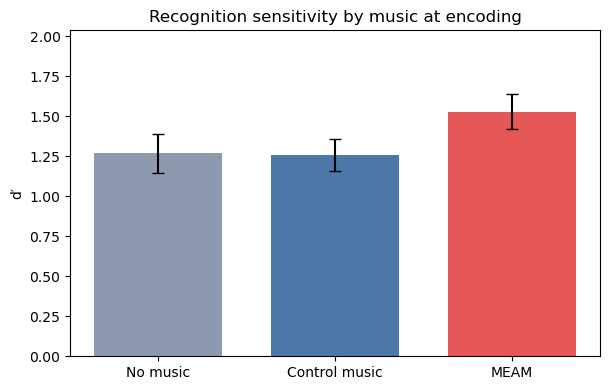

Mean d′ ± SEM
                mean    sem
condition                  
no_music       1.270  0.122
control_music  1.256  0.100
meam           1.527  0.109


In [8]:
means = dprime_wide[condition_order].mean()
sems = dprime_wide[condition_order].sem()
labels = ["No music", "Control music", "MEAM"]
colors = ["#8d99ae", "#4c78a8", "#e45756"]

fig, ax = plt.subplots(figsize=(6.2, 4))
ax.bar(labels, means, yerr=sems, color=colors, capsize=4, width=0.72)
ax.set_ylabel("d′")
ax.set_title("Recognition sensitivity by music at encoding")
ax.set_ylim(0, max(means + sems) + 0.4)
fig.tight_layout()
plt.show()
print("Mean d′ ± SEM")
print(pd.DataFrame({"mean": means, "sem": sems}).round(3).to_string())


## 6. Confidence

Every memory-test video is followed by Sure / Maybe / Guess, including videos they called NEW.
Join that row back onto the OLD/NEW row with `participant`, `list_num`, and `trial_num`.

The six-point scale used for an ROC puts the most confident NEW at 1 and the most confident OLD at 6:

| 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|
| NEW Sure | NEW Maybe | NEW Guess | OLD Guess | OLD Maybe | OLD Sure |


In [9]:
confidence = data[(data.phase == "recall") & (data.question == "confidence")][
    ["participant", "list_num", "trial_num", "response"]
].rename(columns={"response": "confidence"})

memory = recognition[["participant", "list_num", "trial_num", "is_old", "response", "correct"]].rename(
    columns={"response": "old_new"}
)
rated = memory.merge(confidence, on=["participant", "list_num", "trial_num"], how="left")
rated["was_correct"] = rated.correct.eq("1")


def six_point(row):
    if row.old_new == "new" and row.confidence == "sure":
        return 1
    if row.old_new == "new" and row.confidence == "maybe":
        return 2
    if row.old_new == "new" and row.confidence == "guess":
        return 3
    if row.old_new == "old" and row.confidence == "guess":
        return 4
    if row.old_new == "old" and row.confidence == "maybe":
        return 5
    if row.old_new == "old" and row.confidence == "sure":
        return 6
    return np.nan


rated["rating"] = rated.apply(six_point, axis=1)
sure_when_correct = rated.loc[rated.was_correct, "confidence"].eq("sure").mean()
sure_when_wrong = rated.loc[~rated.was_correct & rated.old_new.ne(""), "confidence"].eq("sure").mean()
print(f"P(Sure | correct) = {sure_when_correct:.3f}")
print(f"P(Sure | incorrect) = {sure_when_wrong:.3f}")


P(Sure | correct) = 0.650
P(Sure | incorrect) = 0.364


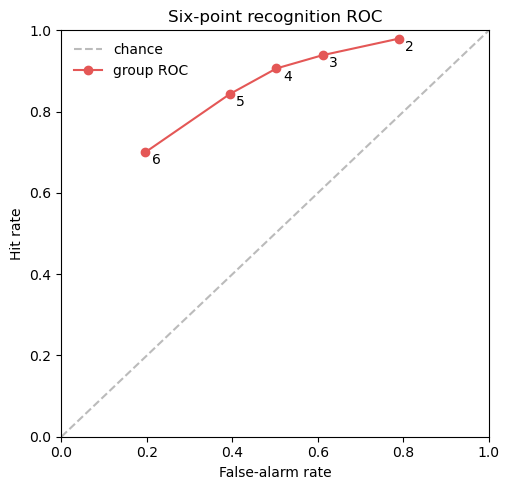

,threshold,hit_rate,fa_rate
0,6,0.700,0.197
1,5,0.843,0.394
2,4,0.906,0.503
3,3,0.939,0.611
4,2,0.979,0.789


In [10]:
roc_rows = []
for threshold in [6, 5, 4, 3, 2]:
    hit_rates = []
    fa_rates = []
    for _, group in rated.dropna(subset=["rating"]).groupby("participant"):
        called_old = group.rating >= threshold
        hit_rates.append(called_old[group.is_old == 1].mean())
        fa_rates.append(called_old[group.is_old == 0].mean())
    roc_rows.append({"threshold": threshold, "hit_rate": np.mean(hit_rates), "fa_rate": np.mean(fa_rates)})
roc = pd.DataFrame(roc_rows)

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color="#bbbbbb", linestyle="--", label="chance")
ax.plot(roc.fa_rate, roc.hit_rate, marker="o", color="#e45756", label="group ROC")
for _, point in roc.iterrows():
    ax.annotate(str(int(point.threshold)), (point.fa_rate + 0.015, point.hit_rate - 0.03))
ax.set_xlabel("False-alarm rate")
ax.set_ylabel("Hit rate")
ax.set_title("Six-point recognition ROC")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
roc.round(3)


## 7. Source memory

Source rows exist only after an OLD response, so false alarms have a source row too.
Score **hits only** (`is_old == 1`). `correct` is 1 when the answer matches the song that actually played:

| Encoding | Correct source answer |
|---|---|
| `no_music` | `no_music` |
| `meam` | `knew` |
| `control_music` | `did_not_know` |


In [11]:
source = data[(data.phase == "recall") & (data.question == "source") & (data.is_old == "1")].copy()
source["source_correct"] = source.correct.eq("1")
source_accuracy = source.groupby("condition").source_correct.mean().reindex(condition_order)
print("Source accuracy given a hit")
print(source_accuracy.round(3).to_string())

expected = {"no_music": "no_music", "meam": "knew", "control_music": "did_not_know"}
source["expected"] = source.condition.map(expected)
confusion = pd.crosstab(source.expected, source.response, normalize="index").reindex(
    index=["no_music", "knew", "did_not_know"],
    columns=["no_music", "knew", "did_not_know"],
)
print("\nRow = what actually played. Column = what they answered. Each row sums to 1.")
confusion.round(3)


Source accuracy given a hit
condition
no_music         0.553
control_music    0.465
meam             0.584

Row = what actually played. Column = what they answered. Each row sums to 1.


response,no_music,knew,did_not_know
expected,,,
no_music,0.553,0.216,0.231
knew,0.215,0.584,0.201
did_not_know,0.267,0.268,0.465


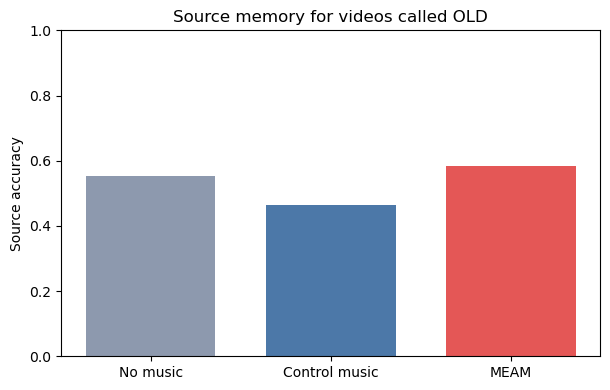

In [12]:
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.bar(labels, source_accuracy.values, color=colors, width=0.72)
ax.set_ylabel("Source accuracy")
ax.set_ylim(0, 1)
ax.set_title("Source memory for videos called OLD")
fig.tight_layout()
plt.show()


## 8. Music survey

Rating rows are `phase == "survey"` and `question` is one of the four item names.
`music_replay` only records that the clip was played. Leave it out of the averages.

A timeout has a blank `response`, a blank `rt_ms`, and `timed_out == 1`. Leave timeouts out of the mean. They are missing ratings, and filling them with 0 or 3 would move the mean.


In [13]:
question_order = ["familiarity", "autobio_memory", "self_relevance", "liking"]
question_labels = ["Familiarity", "Autobiographical\nmemory", "Self-relevance", "Liking"]
survey = data[(data.phase == "survey") & data.question.isin(question_order)].copy()
survey["rating"] = pd.to_numeric(survey.response.replace("", np.nan), errors="coerce")

# One mean per person, then the mean and SEM across people.
person_means = (
    survey.groupby(["participant", "condition", "question"], as_index=False).rating.mean()
)
survey_summary = (
    person_means.groupby(["condition", "question"]).rating.agg(["mean", "sem"]).reset_index()
)
survey_summary.pivot(index="question", columns="condition", values="mean").reindex(question_order).round(3)


condition,control_music,meam
question,,
familiarity,2.251,4.080
autobio_memory,1.630,3.659
self_relevance,2.005,3.219
liking,2.711,3.769


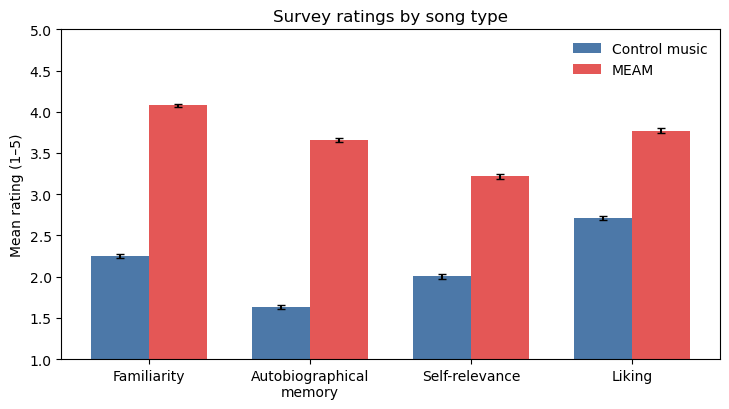

In [14]:
fig, ax = plt.subplots(figsize=(7.4, 4.2))
x = np.arange(len(question_order))
width = 0.36
for offset, condition, label, color in (
    (-width / 2, "control_music", "Control music", "#4c78a8"),
    (width / 2, "meam", "MEAM", "#e45756"),
):
    chunk = survey_summary[survey_summary.condition == condition].set_index("question").reindex(question_order)
    ax.bar(x + offset, chunk["mean"], width, yerr=chunk["sem"], label=label, color=color, capsize=3)
ax.set_xticks(x, question_labels)
ax.set_ylabel("Mean rating (1–5)")
ax.set_ylim(1, 5)
ax.set_title("Survey ratings by song type")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### Do higher ratings go with better memory for the video that played with the song?

`video_file` on a survey row is the encoding video that played with that song. Join it to the old-video recognition row.

An overall comparison (familiar songs remembered better) can be carried entirely by the MEAM condition, because those songs are both more familiar and better remembered. Split by condition before reading it as a rating effect.


In [15]:
clip_ratings = survey.pivot_table(
    index=["participant", "video_file"], columns="question", values="rating"
)
old_videos = recognition.loc[recognition.is_old == 1, ["participant", "video_file", "said_old", "condition"]]
joined = old_videos.merge(clip_ratings, on=["participant", "video_file"], how="left")

within_condition = []
for (participant, condition), group in joined.groupby(["participant", "condition"]):
    within_condition.append({
        "participant": participant,
        "condition": condition,
        "familiarity_when_remembered": group.loc[group.said_old, "familiarity"].mean(),
        "familiarity_when_forgotten": group.loc[~group.said_old, "familiarity"].mean(),
    })
familiarity_by_memory = pd.DataFrame(within_condition)
familiarity_by_memory.groupby("condition")[
    ["familiarity_when_remembered", "familiarity_when_forgotten"]
].mean().reindex(["control_music", "meam"]).round(3)


,familiarity_when_remembered,familiarity_when_forgotten
condition,,
control_music,2.249,2.262
meam,4.080,4.244


## 9. Memorability

`mem_score` is a published memorability score for the video, from the Memento10k norms. It is on the encoding and memory-test rows. It was not shown to the participant.

These 108 videos all sit in a narrow band of scores (roughly 0.75 to 0.90). Each video was old for every analysed participant, so the hit rate is a proportion out of about 20 people. A small memorability effect is easy to miss in that scatter. Report the correlation and the range, and keep the claim matched to what the plot can support.


Videos: 108
mem_score range: 0.752 to 0.899
Correlation of mem_score with hit rate: -0.129


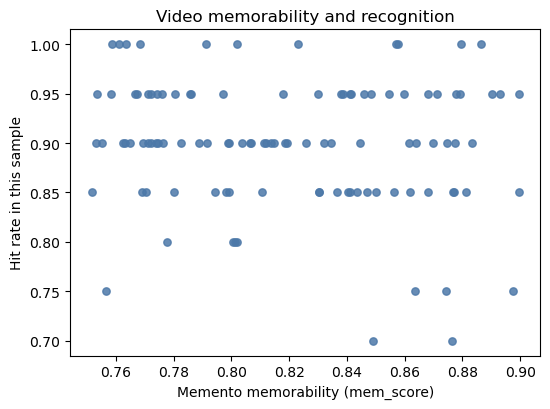

In [16]:
old_memory = recognition.loc[recognition.is_old == 1, ["video_file", "said_old", "mem_score"]].copy()
old_memory["mem_score"] = pd.to_numeric(old_memory.mem_score, errors="coerce")
by_video = old_memory.groupby("video_file", as_index=False).agg(
    mem_score=("mem_score", "first"),
    hit_rate=("said_old", "mean"),
    n=("said_old", "size"),
)
correlation = by_video.mem_score.corr(by_video.hit_rate)
print(f"Videos: {len(by_video)}")
print(f"mem_score range: {by_video.mem_score.min():.3f} to {by_video.mem_score.max():.3f}")
print(f"Correlation of mem_score with hit rate: {correlation:.3f}")

fig, ax = plt.subplots(figsize=(5.6, 4.2))
ax.scatter(by_video.mem_score, by_video.hit_rate, s=28, color="#4c78a8", alpha=0.85)
ax.set_xlabel("Memento memorability (mem_score)")
ax.set_ylabel("Hit rate in this sample")
ax.set_title("Video memorability and recognition")
fig.tight_layout()
plt.show()


## 10. Paired tests

Each person has a d′ in every condition, so the comparison is within person.
`ttest_rel` tests whether the average of those person-by-person differences is 0.


In [17]:
def report_pair(label, left, right):
    # Line the two columns up on participant, then test the within-person difference.
    paired = pd.concat({"left": left, "right": right}, axis=1).dropna()
    difference = paired.left - paired.right
    t_stat, p_value = ttest_rel(paired.left, paired.right)
    print(
        f"{label}: mean difference {difference.mean():.3f} "
        f"(SEM {difference.sem():.3f}), t({len(difference) - 1}) = {t_stat:.2f}, p = {p_value:.4f}"
    )


report_pair("MEAM minus no music", dprime_wide.meam, dprime_wide.no_music)
report_pair("MEAM minus control music", dprime_wide.meam, dprime_wide.control_music)

# Align on participant so each pair is the same person.
source_by_person = source.groupby(["participant", "condition"]).source_correct.mean().unstack("condition")
report_pair(
    "MEAM minus control, source accuracy",
    source_by_person.meam,
    source_by_person.control_music,
)


MEAM minus no music: mean difference 0.257 (SEM 0.101), t(19) = 2.55, p = 0.0196
MEAM minus control music: mean difference 0.271 (SEM 0.094), t(19) = 2.87, p = 0.0098
MEAM minus control, source accuracy: mean difference 0.116 (SEM 0.027), t(19) = 4.26, p = 0.0004


## 11. Check the answer key

`answer_key.json` lists who should be excluded and the range each planted effect should fall in with this sample size.
The ranges are wide on purpose: 20 people and 36 old videos per condition leave a lot of sampling noise around the values that were built in.


In [18]:
excluded = set(summary.loc[summary.exclude, "participant"])
expected_excluded = {item["participant"] for item in answer_key["exclusions"]}
if excluded != expected_excluded:
    raise AssertionError(f"Exclusion mismatch.\nGot {excluded}\nKey {expected_excluded}")

ranges = answer_key["ranges_the_notebook_should_recover"]
meam_vs_none = float((dprime_wide.meam - dprime_wide.no_music).mean())
meam_vs_control = float((dprime_wide.meam - dprime_wide.control_music).mean())
lo, hi = ranges["mean_dprime_meam_minus_no_music"]
if not lo <= meam_vs_none <= hi:
    raise AssertionError(f"MEAM minus no-music d′ {meam_vs_none:.3f} outside {lo}–{hi}")
lo, hi = ranges["mean_dprime_meam_minus_control_music"]
if not lo <= meam_vs_control <= hi:
    raise AssertionError(f"MEAM minus control d′ {meam_vs_control:.3f} outside {lo}–{hi}")

familiarity = person_means[person_means.question == "familiarity"]
gaps = []
for _, group in familiarity.groupby("participant"):
    meam_rating = group.loc[group.condition.eq("meam"), "rating"].mean()
    control_rating = group.loc[group.condition.eq("control_music"), "rating"].mean()
    gaps.append(meam_rating - control_rating)
familiarity_gap = float(np.mean(gaps))
lo, hi = ranges["mean_familiarity_meam_minus_control"]
if not lo <= familiarity_gap <= hi:
    raise AssertionError(f"Familiarity gap {familiarity_gap:.3f} outside {lo}–{hi}")

true_dprime = {
    item["participant"]: item["true_dprime"]
    for item in answer_key["participants"]
    if item["true_dprime"] is not None and item["participant"] in keep_ids
}
recovered = dprime_wide.no_music.loc[list(true_dprime)]
truth = pd.Series(true_dprime)
correlation = float(truth.corr(recovered))
minimum = ranges["correlation_of_true_dprime_with_recovered_no_music_dprime_at_least"]
if correlation < minimum:
    raise AssertionError(f"d′ correlation {correlation:.3f} below {minimum}")

print("Answer-key checks passed.")
print(f"  MEAM − no music d′ = {meam_vs_none:.3f}")
print(f"  MEAM − control d′ = {meam_vs_control:.3f}")
print(f"  MEAM − control familiarity = {familiarity_gap:.3f}")
print(f"  Correlation of planted d′ with no-music d′ = {correlation:.3f}")
print(f"  Analysed n = {len(keep_ids)}")


Answer-key checks passed.
  MEAM − no music d′ = 0.257
  MEAM − control d′ = 0.271
  MEAM − control familiarity = 1.828
  Correlation of planted d′ with no-music d′ = 0.747
  Analysed n = 20


## Exercises

Try these before opening the notes. The following cell prints the numbers.

<details>
<summary>1. A high "old" rate</summary>

Among the people you kept, find the one with the highest modal OLD/NEW rate.
Compute their hit rate and their false-alarm rate separately.
A high "old" rate can be a liberal guessing style. d′ is the gap between hits and false alarms, so someone can say OLD often and still be measured fairly.
</details>

<details>
<summary>2. Survey timeouts</summary>

For the inattentive participant, count rating rows with `timed_out == 1`.
A timeout is stored as a blank `response`, a blank `rt_ms`, and `timed_out` of 1. Leave those rows out of rating means.
</details>

<details>
<summary>3. The wrong audio-check word</summary>

That same person has `wrong_audio_checks == 1`, and they still have a full set of encoding rows.
The task logged the mistake and continued. Use the attention measures in the exclusion table to decide, and keep a single mistyped word from automatically dropping an otherwise careful session.
</details>

<details>
<summary>4. Source confusions</summary>

Among no-music videos that were recognized as old, tabulate `response` on the source rows.
The correct answer is `no_music`. The share of `knew` answers is the rate at which people claim they knew a song that was never played.
</details>

<details>
<summary>5. Forgetting to filter</summary>

On a plugin recognition row, `response` is `arrowleft` or `arrowright`.
On the tidy row for the same trial, `response` is `old` or `new`.
Averaging `response` on the raw file mixes those two codes in one column. Filter to `row_type == "trial"` first.
</details>


In [19]:
# Exercise results. Each print is the quantity described above.
kept = summary.loc[~summary.exclude].sort_values("modal_old_new_rate", ascending=False)
liberal = kept.iloc[0]
liberal_trials = recognition[recognition.participant.eq(liberal.participant)]
liberal_hit = liberal_trials.loc[liberal_trials.is_old.eq(1), "said_old"].mean()
liberal_fa = liberal_trials.loc[liberal_trials.is_old.eq(0), "said_old"].mean()
print(f"1. {liberal.participant[:8]}… hit rate {liberal_hit:.3f}, false-alarm rate {liberal_fa:.3f}")

inattentive_id = summary.loc[summary.exclude_reason.str.contains("inattentive"), "participant"].iloc[0]
inattentive_rows = all_rows[all_rows.participant.eq(inattentive_id) & all_rows.row_type.eq("trial")]
timeouts = inattentive_rows[
    inattentive_rows.phase.eq("survey")
    & ~inattentive_rows.question.isin(["", "music_replay"])
    & inattentive_rows.timed_out.eq("1")
]
print(f"2. Inattentive participant timed out of {len(timeouts)} rating questions")
print(f"3. Wrong audio checks: {int((inattentive_rows.question.eq('typed_word') & inattentive_rows.correct.eq('0')).sum())}; "
      f"encoding rows: {(inattentive_rows.question == 'person_count').sum()}")

no_music_hits = source[source.condition.eq("no_music")]
knew_share = no_music_hits.response.eq("knew").mean()
print(f"4. No-music hits called 'knew': {knew_share:.3f}")

plugin_keys = raw_one.loc[
    raw_one.subphase.eq("recognition") & raw_one.response.ne("null"), "response"
].unique()
print("5. Plugin recognition responses:", sorted(plugin_keys)[:4])

if not (liberal_hit > 0.90 and liberal_fa > 0.50):
    raise AssertionError("Exercise 1 did not find a liberal responder")
if len(timeouts) < 80:
    raise AssertionError("Exercise 2 timeout count looks too low")
if knew_share < 0.10 or knew_share > 0.40:
    raise AssertionError("Exercise 4 knew-share is outside the planted range")
print("Exercise checks passed.")


1. 670c02d5… hit rate 0.963, false-alarm rate 0.694
2. Inattentive participant timed out of 119 rating questions
3. Wrong audio checks: 1; encoding rows: 108
4. No-music hits called 'knew': 0.216
5. Plugin recognition responses: ['arrowleft', 'arrowright']
Exercise checks passed.


## What to do with a real Pavlovia download

1. Put the CSVs in a folder and point `DATA` at it. Real files use the same name pattern: `music-memory-prolific_<id>_SESSION_<date>.csv`.
2. Keep rows with `row_type` filled in. The plugin rows are useful when you need to see the raw key or the HTML that was on screen.
3. Run the same exclusion table before any means. Add the real completion code and any extra rules your lab agrees on, and write the rule down in the exclusion table.
4. There is one false-alarm rate per person. Lures have no music condition.
5. `answer_key.json` applies only to these practice files. A real dataset has no planted d′ to check against.
